# 17. Low-Rank Approximation, PCA and Rayleigh Quotients
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Orthogonal regression versus ordinary least squares on the same centred data. PCA's first component (blue) minimizes the perpendicular distances (thin blue segments); least squares of $y$ on $x$ (gold) minimizes the vertical distances and is flatter. The two coincide only when the data lie exactly on a line.

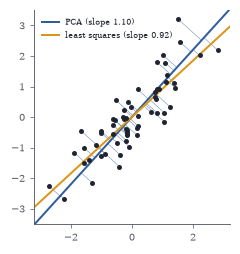

In [2]:
rng = np.random.default_rng(4); n = 60
t = rng.normal(size=n); X = np.vstack([t + 0.45 * rng.normal(size=n), 1.2 * t + 0.45 * rng.normal(size=n)])
X = X - X.mean(axis=1, keepdims=True)
U, s, Vt = np.linalg.svd(X, full_matrices=False); u1 = U[:, 0] * np.sign(U[0, 0])
slope_ls = (X[0] @ X[1]) / (X[0] @ X[0])
fig, ax = plt.subplots(figsize=(W * 0.6, 2.2))
proj = np.outer(u1, u1 @ X)
for k in range(n):
    ax.plot([X[0, k], proj[0, k]], [X[1, k], proj[1, k]], color=BLUE, lw=0.35, alpha=0.7)
ax.scatter(*X, s=5, color=INK, zorder=3)
xx = np.linspace(-3.2, 3.2, 2)
ax.plot(xx, u1[1] / u1[0] * xx, color=BLUE, lw=1.3, label=f"PCA (slope {u1[1] / u1[0]:.2f})")
ax.plot(xx, slope_ls * xx, color=GOLD, lw=1.3, label=f"least squares (slope {slope_ls:.2f})")
ax.set_aspect("equal"); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.5, 3.5); ax.legend(fontsize=5.5, loc="upper left")

Scree plots. Left: computed singular values of the $40\times40$ Hilbert matrix, falling exponentially until they hit the floor of rounding error near $10^{-16}$; the elbow gives an effective rank of about $17$. Right: a $200\times100$ data matrix of rank $5$ plus noise; five singular values stand above a flat noise bulk.

Text(0.5, 1.0, 'rank 5 plus noise')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


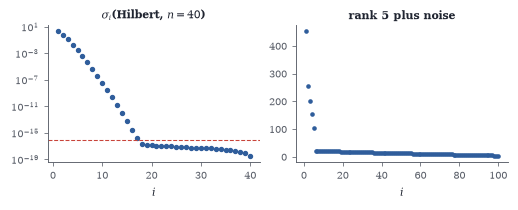

In [3]:
from scipy.linalg import hilbert
sH = np.linalg.svd(hilbert(40), compute_uv=False)
rng = np.random.default_rng(1); D = rng.normal(size=(200, 5)) @ np.diag([30, 20, 14, 10, 7]) @ rng.normal(size=(5, 100)) / 10 + rng.normal(size=(200, 100))
sD = np.linalg.svd(D, compute_uv=False)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.8))
axs[0].semilogy(range(1, 41), sH, "o", color=BLUE, ms=2.5); axs[0].axhline(1e-16, color=RED, ls="--", lw=0.7); axs[0].set_xlabel("$i$"); axs[0].set_title(r"$\sigma_i$(Hilbert, $n=40$)", fontsize=7)
axs[1].plot(range(1, 101), sD, "o", color=BLUE, ms=2); axs[1].set_xlabel("$i$"); axs[1].set_title("rank 5 plus noise", fontsize=7)

PCA rediscovers Fourier modes. Each sample is a random smooth periodic signal of length $64$ (a random shift of random bumps), so its covariance depends only on the offset between positions. The first eight principal components (left, stacked) are the constant mode followed by sine and cosine pairs of increasing frequency, and after the first the explained variances (right) come in equal pairs, tracing out the power spectrum.

Text(0.5, 1.0, 'explained variance')

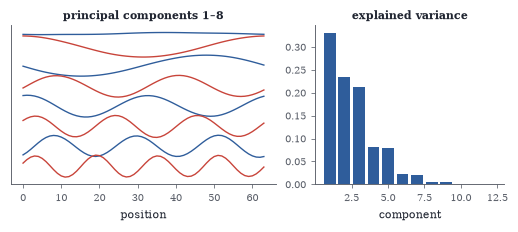

In [4]:
rng = np.random.default_rng(3); L = 64; N = 3000; grid = np.arange(L)
Xs = np.zeros((N, L))
for i in range(N):
    for _ in range(3):
        c = rng.uniform(0, L); w = rng.uniform(3, 8); d = np.minimum(np.abs(grid - c), L - np.abs(grid - c))
        Xs[i] += rng.normal() * np.exp(-d ** 2 / (2 * w ** 2))
Xs = Xs - Xs.mean(0); Ux, sx, Vx = np.linalg.svd(Xs, full_matrices=False)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0), gridspec_kw={"width_ratios": [1.4, 1]})
for k in range(8):
    axs[0].plot(grid, Vx[k] * 3 - 1.0 * k, color=[BLUE, RED][k % 2], lw=0.9)
axs[0].set_yticks([]); axs[0].set_xlabel("position"); axs[0].set_title("principal components 1–8", fontsize=7)
axs[1].bar(range(1, 13), (sx ** 2 / np.sum(sx ** 2))[:12], color=BLUE); axs[1].set_xlabel("component"); axs[1].set_title("explained variance", fontsize=7)

In [5]:
A = np.array([[3, -4, 7, 1, -4, -3], [7, -6, 8, -1, -1, -7.]])
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print("variances along components:", (s ** 2 / 5).round(4), "  fraction explained:", (s ** 2 / np.sum(s ** 2)).round(4))
print("first principal component u1 =", (U[:, 0] * np.sign(U[0, 0])).round(4), "  scores u1^T a_k =", (np.sign(U[0, 0]) * U[:, 0] @ A).round(3))

variances along components: [56.9258  3.0742]   fraction explained: [0.9488 0.0512]
first principal component u1 = [0.5606 0.8281]   scores u1^T a_k = [ 7.478 -7.211 10.549 -0.267 -3.071 -7.478]


Ranks of matrices of ones that draw shapes. Left: a quarter disc of ones of radius $N=60$. Right: the numerical rank of the quarter-disc matrix as $N$ grows (blue), against the prediction $(2-\sqrt2)N$ (dashed); the square block has rank $1$ and the triangle rank $N$ for comparison.

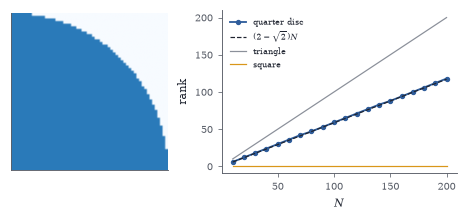

In [6]:
def qdisc(N):
    i, j = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")
    return ((i + 0.5) ** 2 + (j + 0.5) ** 2 <= N ** 2).astype(float)
Ns = np.arange(10, 201, 10); rk = [np.linalg.matrix_rank(qdisc(N)) for N in Ns]
fig, axs = plt.subplots(1, 2, figsize=(W * 0.9, 1.9), gridspec_kw={"width_ratios": [1, 1.5]})
axs[0].imshow(qdisc(60)[::-1], cmap="Blues", vmin=0, vmax=1.4); axs[0].set_xticks([]); axs[0].set_yticks([])
axs[1].plot(Ns, rk, "o-", color=BLUE, ms=2.5, label="quarter disc"); axs[1].plot(Ns, (2 - np.sqrt(2)) * Ns, "--", color=INK, lw=0.8, label=r"$(2-\sqrt{2})N$")
axs[1].plot(Ns, Ns, color=GRAY, lw=0.8, label="triangle"); axs[1].plot(Ns, np.ones_like(Ns), color=GOLD, lw=0.8, label="square")
axs[1].set_xlabel("$N$"); axs[1].set_ylabel("rank"); axs[1].legend(fontsize=5.5)

The Rayleigh quotient of $S=\mathrm{diag}(3,2,1)$ on the unit sphere, shown on the upper hemisphere seen from above. The maximum (at $\pm e_1$, red) and minimum (at $\pm e_3$, the centre, blue) are the only local extrema; the eigenvector $e_2$ for the middle eigenvalue (gold) is a saddle point, through which passes the level curve $R=2$ (black) separating the basin of the minimum from the regions around the maximum.

(np.float64(-1.1),
 np.float64(1.0),
 np.float64(-0.9999922506833704),
 np.float64(0.9999922506833704))

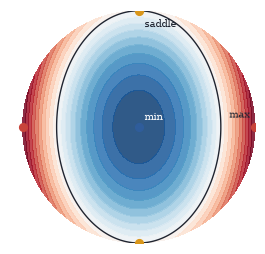

In [7]:
lam = np.array([3.0, 2.0, 1.0])
r = np.linspace(0, 1, 300); th = np.linspace(0, 2 * np.pi, 400); RR, TH = np.meshgrid(r, th)
x1, x2 = RR * np.cos(TH), RR * np.sin(TH); x3 = np.sqrt(np.maximum(1 - RR ** 2, 0))
Rq = lam[0] * x1 ** 2 + lam[1] * x2 ** 2 + lam[2] * x3 ** 2
fig, ax = plt.subplots(figsize=(W * 0.5, W * 0.5))
cs = ax.contourf(x1, x2, Rq, levels=20, cmap="RdBu_r", alpha=0.85); ax.contour(x1, x2, Rq, levels=[2.0], colors=[INK], linewidths=0.9)
ax.plot([1, -1], [0, 0], "o", color=RED, ms=5); ax.plot([0, 0], [1, -1], "o", color=GOLD, ms=5); ax.plot(0, 0, "o", color=BLUE, ms=5)
ax.text(0.78, 0.08, "max", fontsize=6.5); ax.text(0.05, 0.86, "saddle", fontsize=6.5); ax.text(0.05, 0.06, "min", fontsize=6.5, color="white")
ax.set_aspect("equal"); ax.axis("off")

In [8]:
from scipy.linalg import eigh
S = np.array([[4, -2], [-2, 4.]]); M = np.diag([1, 2.])
lam, X = eigh(S, M)                       # generalized symmetric-definite problem
print("eigenvalues:", lam, " vs 3 -+ sqrt3:", 3 - np.sqrt(3), 3 + np.sqrt(3))
print("X^T M X =\n", (X.T @ M @ X).round(12), "\nX^T S X =\n", (X.T @ S @ X).round(12))

eigenvalues: [1.26794919 4.73205081]  vs 3 -+ sqrt3: 1.2679491924311228 4.732050807568877
X^T M X =
 [[1. 0.]
 [0. 1.]] 
X^T S X =
 [[1.26794919 0.        ]
 [0.         4.73205081]]


Simultaneous diagonalization. Left: the ellipse $x^{\mathsf T}Mx=1$ (blue) and the ellipse $x^{\mathsf T}Sx=1$ (red) for the masses-and-springs example, with the generalized eigenvectors $x_1,x_2$ (scaled to $x^{\mathsf T}Mx=1$). They are not perpendicular, but they are conjugate diameters of both ellipses. Right: in the coordinates $y=X^{-1}x$ both ellipses become axis-aligned: a circle and an ellipse with semi-axes $1/\sqrt{\lambda_k}$.

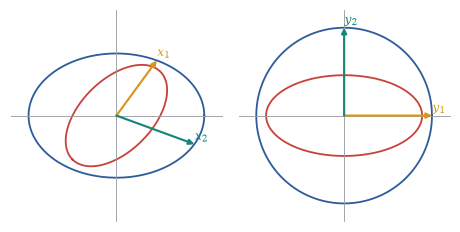

In [9]:
S = np.array([[4, -2], [-2, 4.]]); M = np.diag([1, 2.]); lam, X = eigh(S, M)
t = np.linspace(0, 2 * np.pi, 300); C = np.vstack([np.cos(t), np.sin(t)])
def ell(Q):
    w, V = np.linalg.eigh(Q); return V @ np.diag(1 / np.sqrt(w)) @ C
fig, axs = plt.subplots(1, 2, figsize=(W * 0.9, 2.0))
ax = axs[0]; plane(ax, 1.2, grid=False); ax.plot(*ell(M), color=BLUE); ax.plot(*ell(S), color=RED)
for k, col in [(0, GOLD), (1, TEAL)]:
    arrow(ax, X[:, k] * np.sign(X[0, k]), color=col, label=f"$x_{k + 1}$")
ax = axs[1]; plane(ax, 1.2, grid=False); ax.plot(*C, color=BLUE); ax.plot(*(np.diag(1 / np.sqrt(lam)) @ C), color=RED)
arrow(ax, [1, 0], color=GOLD, label="$y_1$"); arrow(ax, [0, 1], color=TEAL, label="$y_2$")

Fisher's discriminant versus PCA on two elongated classes. The first principal component of the pooled data (gold) points along the long axis of the clouds, and projecting onto it mixes the classes (gold histograms). Fisher's direction $w=S_W^{-1}(\mu_1-\mu_2)$ (blue) separates them well (blue histograms); it is tilted away from the mean difference $\mu_1-\mu_2$ towards the direction in which the clouds are thinnest.

Text(0.02, 0.4, 'Fisher')

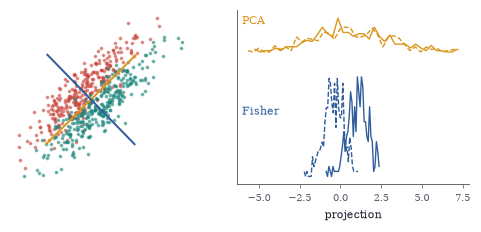

In [10]:
rng = np.random.default_rng(5); Sig = np.array([[3.0, 2.6], [2.6, 3.0]]); Lc = np.linalg.cholesky(Sig)
mu1, mu2 = np.array([-0.2, 1.3]), np.array([0.7, 0.0])
P1 = (Lc @ rng.normal(size=(2, 300))).T + mu1; P2 = (Lc @ rng.normal(size=(2, 300))).T + mu2
w = np.linalg.solve(2 * Sig, mu1 - mu2); w /= np.linalg.norm(w)
allp = np.vstack([P1, P2]); allp = allp - allp.mean(0); pc = np.linalg.svd(allp, full_matrices=False)[2][0]
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axs[0]; ax.scatter(*P1.T, s=2, color=RED, alpha=0.5); ax.scatter(*P2.T, s=2, color=TEAL, alpha=0.5)
c0 = allp.mean(0) + np.vstack([P1, P2]).mean(0)
for d, col in [(pc, GOLD), (w, BLUE)]:
    ax.plot(*np.c_[c0 - 4 * d, c0 + 4 * d], color=col, lw=1.3)
ax.set_aspect("equal"); ax.axis("off")
ax = axs[1]
for d, col, off in [(w, BLUE, 0), (pc, GOLD, 1.0)]:
    for P, ls in [(P1, "-"), (P2, "--")]:
        h, e = np.histogram(P @ d, bins=40, density=True); ax.plot(0.5 * (e[1:] + e[:-1]), h + off, color=col, ls=ls, lw=0.9)
ax.set_yticks([]); ax.set_xlabel("projection"); ax.text(0.02, 0.92, "PCA", color=GOLD, fontsize=7, transform=ax.transAxes); ax.text(0.02, 0.4, "Fisher", color=BLUE, fontsize=7, transform=ax.transAxes)

In [11]:
rng = np.random.default_rng(0)
A = rng.normal(size=(5, 5)) @ np.diag([1, 1e-3, 1e-6, 1e-9, 1e-12]) @ np.linalg.qr(rng.normal(size=(5, 5)))[0]
print("SVD of A        :", np.linalg.svd(A, compute_uv=False))
print("sqrt eig(A A^T) :", np.sqrt(np.abs(np.sort(np.linalg.eigvalsh(A @ A.T))[::-1])))

SVD of A        : [1.04296076e+00 1.86872707e-03 1.60186499e-06 7.52761282e-10
 9.41643707e-13]
sqrt eig(A A^T) : [1.04296076e+00 1.86872707e-03 1.60185739e-06 8.10244437e-09
 1.12757069e-09]


In [12]:
from scipy.linalg import eigh
S = np.array([[5, 4], [4, 5.]]); M = np.diag([1, 0.25])
lam, X = eigh(S, M); H = np.diag([1, 2.]) @ S @ np.diag([1, 2.]); mu, Y = np.linalg.eigh(H)
print("generalized eigenvalues:", lam.round(4), "  eigenvalues of H:", mu.round(4))
print("x1.x2 =", round(X[:, 0] @ X[:, 1], 4), "  x1^T M x2 =", round(X[:, 0] @ M @ X[:, 1], 12), "  y1.y2 =", round(Y[:, 0] @ Y[:, 1], 12))
print("X = M^(-1/2) Y up to scaling:", np.allclose(np.abs(np.diag([1, 2.]) @ Y / np.linalg.norm(np.diag([1, 2.]) @ Y, axis=0)), np.abs(X / np.linalg.norm(X, axis=0))))

generalized eigenvalues: [ 1.5341 23.4659]   eigenvalues of H: [ 1.5341 23.4659]
x1.x2 = 1.0943   x1^T M x2 = 0.0   y1.y2 = 0.0
X = M^(-1/2) Y up to scaling: True
